# Characterizing LLM-based agent executions by task outcome

Reproducible analysis for the paper *"Characterizing LLM-Based Agent Executions by Task Outcome: A Data Mining Study on Telemetry Data"* (PPCA/UnB, Data Mining course).

**Question.** Do successful and unsuccessful executions show distinct execution behavior in the attributes recorded by telemetry (steps, execution time, tokens)?

**Data.** [`Exgentic/agent-llm-traces-v2`](https://huggingface.co/datasets/Exgentic/agent-llm-traces-v2): 10,056 agent executions following the OpenTelemetry semantic conventions for generative AI.

**Method.** CRISP-DM, within a Design Science Research methodology. Groups are compared with the Mann-Whitney test and the probability of superiority (PS), with 95% bootstrap compatibility intervals (1,000 resamples, fixed seed).

| Phase | Section |
|---|---|
| Business understanding | 1 |
| Data understanding | 2 |
| Data preparation | 3 |
| Modeling | 4 |
| Evaluation | 5 |
| Deployment | 6 |

---
# 1. Business understanding

LLM-based agents are becoming part of the digital customer journeys of financial institutions such as Banco do Brasil. In production, no verifier reports whether the agent solved the task, and operations teams only see telemetry. This study checks whether telemetry attributes carry information about the task outcome, and which attributes match the OpenTelemetry standard, a condition for applying the procedure to the institution's own traces.

**Success criterion.** Characterize the attributes, verify their correspondence with the standard and compare the outcome groups, even if the differences turn out to be small. A null result is also reported.

---
# 2. Data understanding

## 2.1 Setup

In [1]:
import os
import requests
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import pyarrow.compute as pc
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

COLOR_SUCCESS = "#2a78d6"
COLOR_FAILURE = "#e8743b"

## 2.2 Load the data

The dataset has 9 parquet files (~230 MB). They are downloaded once into `DATA_DIR` (default `data/`).

In [2]:
URL = ("https://huggingface.co/datasets/Exgentic/agent-llm-traces-v2"
       "/resolve/main/data/train/{:04d}.parquet")
DATA_DIR = os.environ.get("DATA_DIR", "data")
os.makedirs(DATA_DIR, exist_ok=True)

for i in range(9):
    path = f"{DATA_DIR}/{i:04d}.parquet"
    if not os.path.exists(path):
        with requests.get(URL.format(i), stream=True, timeout=300) as r:
            r.raise_for_status()
            with open(path, "wb") as f:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)

FILES = sorted(f"{DATA_DIR}/{name}" for name in os.listdir(DATA_DIR) if name.endswith(".parquet"))
COLUMNS = ["session_id", "benchmark", "harness", "models", "score", "success", "status",
           "steps", "action_count", "execution_time", "total_tokens", "agent_cost"]

df = pd.concat([pd.read_parquet(f, columns=COLUMNS) for f in FILES], ignore_index=True)
df["model"] = df["models"].str[0].str.replace("-2025-12-11", "", regex=False)
print("Executions:", len(df))

Executions: 10056


Attributes used: `steps`, `execution_time` (seconds) and `total_tokens`. Outcome: `success`. Grouping fields: `benchmark` (task set), `model` and `harness`. `agent_cost` (not recorded by the standard) and `action_count` (harness-dependent) are not analyzed.

In [3]:
CATEGORICAL = ["model", "harness", "benchmark"]
ATTRIBUTES = ["steps", "execution_time", "total_tokens"]
NAMES = {"steps": "Steps", "execution_time": "Execution time (s)", "total_tokens": "Tokens"}
OUTCOME = "success"

## 2.3 Structure

In [4]:
print("Rows, columns:", df.shape)
print("Unique session_id:", df["session_id"].is_unique)
print(df["benchmark"].value_counts().sort_index(), "\n")
print(df["model"].value_counts(), "\n")
print(df["harness"].value_counts())

Rows, columns: (10056, 13)
Unique session_id: True
benchmark
appworld          1500
browsecompplus    1948
swebench          1959
tau2_airline       957
tau2_retail       1848
tau2_telecom      1844
Name: count, dtype: int64 

model
DeepSeek-V3.2           2299
Kimi-K2.5               2285
gpt-5.2                 2124
claude-opus-4-5         1920
gemini-3-pro-preview    1428
Name: count, dtype: int64 

harness
tool_calling                      2643
openai_solo                       2608
smolagents_code                   2434
claude_code                       2071
tool_calling_with_shortlisting     300
Name: count, dtype: int64


In [5]:
pd.crosstab(df["benchmark"], df["model"])

model,DeepSeek-V3.2,Kimi-K2.5,claude-opus-4-5,gemini-3-pro-preview,gpt-5.2
benchmark,,,,,
appworld,500,500,200,300,0
browsecompplus,400,399,351,398,400
swebench,399,390,379,393,398
tau2_airline,200,200,197,79,281
tau2_retail,400,397,397,129,525
tau2_telecom,400,399,396,129,520


## 2.4 Missing and inconsistent fields

In [6]:
df[CATEGORICAL + ATTRIBUTES + [OUTCOME]].isna().sum()

model             0
harness           0
benchmark         0
steps             0
execution_time    0
total_tokens      0
success           0
dtype: int64

In [7]:
# Successful executions with score = 0 (inconsistent outcome field)
inconsistent = (df["score"] == 0) & df["success"]
inconsistency = pd.DataFrame({
    "successes": df.groupby("benchmark")["success"].sum(),
    "successes_with_score_0": inconsistent.groupby(df["benchmark"]).sum(),
})
inconsistency["percent"] = (100 * inconsistency["successes_with_score_0"] / inconsistency["successes"]).round(1)
inconsistency

,successes,successes_with_score_0,percent
benchmark,,,
appworld,372,0,0.0
browsecompplus,843,0,0.0
swebench,1803,609,33.8
tau2_airline,503,0,0.0
tau2_retail,1175,11,0.9
tau2_telecom,1133,0,0.0


In [8]:
pd.crosstab(df["status"], df["success"], margins=True)

success,False,True,All
status,,,
error,260,0,260
limit_reached,29,0,29
success,0,2237,2237
unfinished,369,1,370
unknown,1354,3591,4945
unsuccessful,2215,0,2215
All,4227,5829,10056


## 2.5 Correspondence with the OpenTelemetry standard

For each execution, the OpenTelemetry records (one per model call) give the number of model calls, the time span covered (first start to last end) and the sum of `gen_ai.usage.input_tokens` and `gen_ai.usage.output_tokens`. These are compared with the dataset's precomputed columns. Only the needed fields are read, without message contents.

In [9]:
def read_records(path):
    '''Summarize the OTel records of one parquet file per execution.'''
    pf = pq.ParquetFile(path)
    paths = [pf.schema.column(i).path for i in range(len(pf.schema))]
    fields = [p for p in paths if p.startswith("spans") and
              p.endswith((".start_time", ".end_time", ".input_tokens", ".output_tokens"))]
    table = pf.read(columns=["session_id"] + fields)
    spans = table.column("spans").combine_chunks()
    parent = pc.list_parent_indices(spans)
    flat = pc.list_flatten(spans)
    attrs = pc.struct_field(flat, "attributes")
    r = pd.DataFrame({
        "execution": parent.to_numpy(),
        "start": pd.to_datetime(pc.struct_field(flat, "start_time").to_pandas(), format="ISO8601", utc=True),
        "end": pd.to_datetime(pc.struct_field(flat, "end_time").to_pandas(), format="ISO8601", utc=True),
        "input_tokens": pc.struct_field(attrs, "gen_ai.usage.input_tokens").to_pandas(),
        "output_tokens": pc.struct_field(attrs, "gen_ai.usage.output_tokens").to_pandas(),
    })
    s = r.groupby("execution").agg(calls=("start", "size"), start=("start", "min"), end=("end", "max"),
                                   input_tokens=("input_tokens", "sum"), output_tokens=("output_tokens", "sum"))
    s["session_id"] = table.column("session_id").to_pandas().iloc[s.index].values
    return s

otel = pd.concat([read_records(f) for f in FILES], ignore_index=True)
otel["tokens_otel"] = otel["input_tokens"] + otel["output_tokens"]
otel["time_otel"] = (otel["end"] - otel["start"]).dt.total_seconds()

check = df.merge(otel[["session_id", "calls", "time_otel", "tokens_otel"]], on="session_id", how="left")
check["tokens_equal"] = (check["tokens_otel"] - check["total_tokens"]).abs() <= 1
check["steps_equal"] = check["steps"] == check["calls"]
check["time_ratio"] = check["time_otel"] / check["execution_time"].where(check["execution_time"] > 0)

def summarize_check(g):
    return pd.Series({
        "executions": len(g),
        "tokens equal (%)": round(100 * g["tokens_equal"].mean(), 1),
        "steps = model calls (%)": round(100 * g["steps_equal"].mean(), 1),
        "time covered (median)": round(g["time_ratio"].median(), 2),
    })

correspondence = pd.DataFrame({h: summarize_check(g) for h, g in check.groupby("harness")}).T
correspondence.loc["ALL"] = summarize_check(check)
correspondence["executions"] = correspondence["executions"].astype(int)
correspondence

,executions,tokens equal (%),steps = model calls (%),time covered (median)
claude_code,2071,100.0,16.0,0.85
openai_solo,2608,100.0,14.3,0.76
smolagents_code,2434,100.0,26.1,0.90
tool_calling,2643,100.0,96.0,0.90
tool_calling_with_shortlisting,300,100.0,0.0,0.98
ALL,10056,100.0,38.5,0.86


In [10]:
print("Spearman, steps vs model calls:", round(check["steps"].corr(check["calls"], method="spearman"), 3))
print("Spearman, execution time vs OTel time:", round(check["execution_time"].corr(check["time_otel"], method="spearman"), 3))
print("Spearman, tokens vs OTel tokens:", round(check["total_tokens"].corr(check["tokens_otel"], method="spearman"), 3))

Spearman, steps vs model calls: 0.901
Spearman, execution time vs OTel time: 0.836
Spearman, tokens vs OTel tokens: 1.0


Tokens match the standard exactly; time is approximated by the model-call records; steps are counted by each harness and should be computed as the number of model calls when applying the procedure to other OpenTelemetry traces.

## 2.6 Descriptive statistics

In [11]:
def describe(data):
    return pd.DataFrame({
        "min": data[ATTRIBUTES].min(),
        "Q1": data[ATTRIBUTES].quantile(0.25),
        "median": data[ATTRIBUTES].median(),
        "Q3": data[ATTRIBUTES].quantile(0.75),
        "max": data[ATTRIBUTES].max(),
        "skewness": data[ATTRIBUTES].apply(stats.skew),
    }).rename(index=NAMES).round(2)

describe(df)

,min,Q1,median,Q3,max,skewness
Steps,0.00,9.00,14.00,27.00,201.00,2.97
Execution time (s),0.01,39.75,144.95,462.51,20766.46,5.98
Tokens,0.00,54051.00,233001.50,796400.00,75478081.00,9.96


In [12]:
print(f"Overall success rate: {df[OUTCOME].mean():.1%}\n")
print((100 * df.groupby("benchmark")[OUTCOME].mean()).round(1))

Overall success rate: 58.0%

benchmark
appworld          24.8
browsecompplus    43.3
swebench          92.0
tau2_airline      52.6
tau2_retail       63.6
tau2_telecom      61.4
Name: success, dtype: float64


In [13]:
(100 * pd.crosstab(df["benchmark"], df["model"], values=df[OUTCOME], aggfunc="mean")).round(1)

model,DeepSeek-V3.2,Kimi-K2.5,claude-opus-4-5,gemini-3-pro-preview,gpt-5.2
benchmark,,,,,
appworld,7.0,9.2,64.5,54.0,NaN
browsecompplus,33.8,39.6,56.4,47.5,40.8
swebench,79.2,81.8,100.0,99.7,99.7
tau2_airline,41.0,32.5,69.0,70.9,58.4
tau2_retail,60.8,35.0,80.9,80.6,70.1
tau2_telecom,58.5,38.3,73.2,72.1,69.8


## 2.7 Distributions (log scale; zero values are not shown)

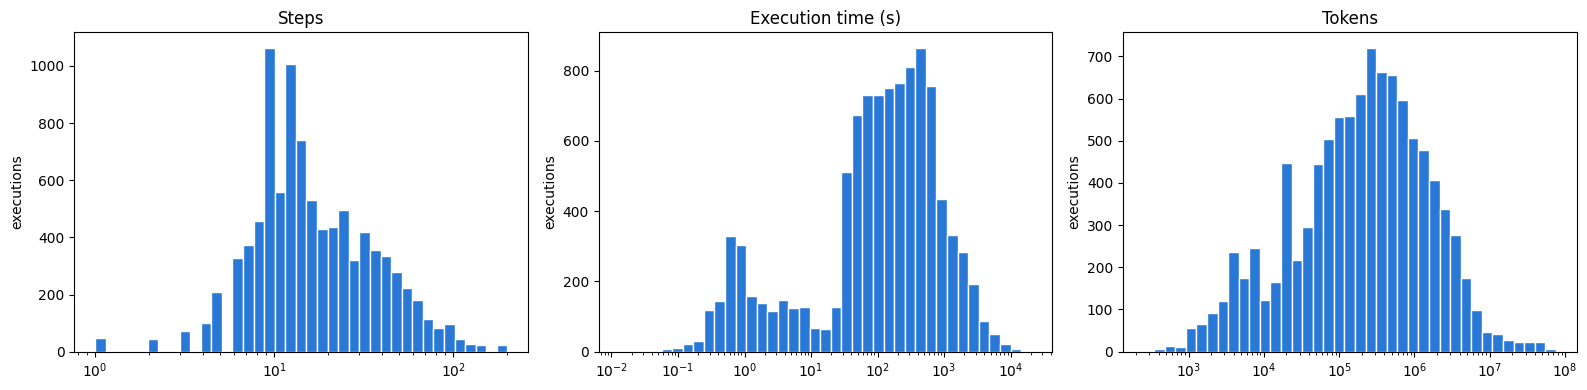

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ATTRIBUTES):
    values = df.loc[df[col] > 0, col]
    bins = np.logspace(np.log10(values.min()), np.log10(values.max()), 40)
    ax.hist(values, bins=bins, color=COLOR_SUCCESS, edgecolor="white")
    ax.set_xscale("log"); ax.set_title(NAMES[col]); ax.set_ylabel("executions")
plt.tight_layout(); plt.show()

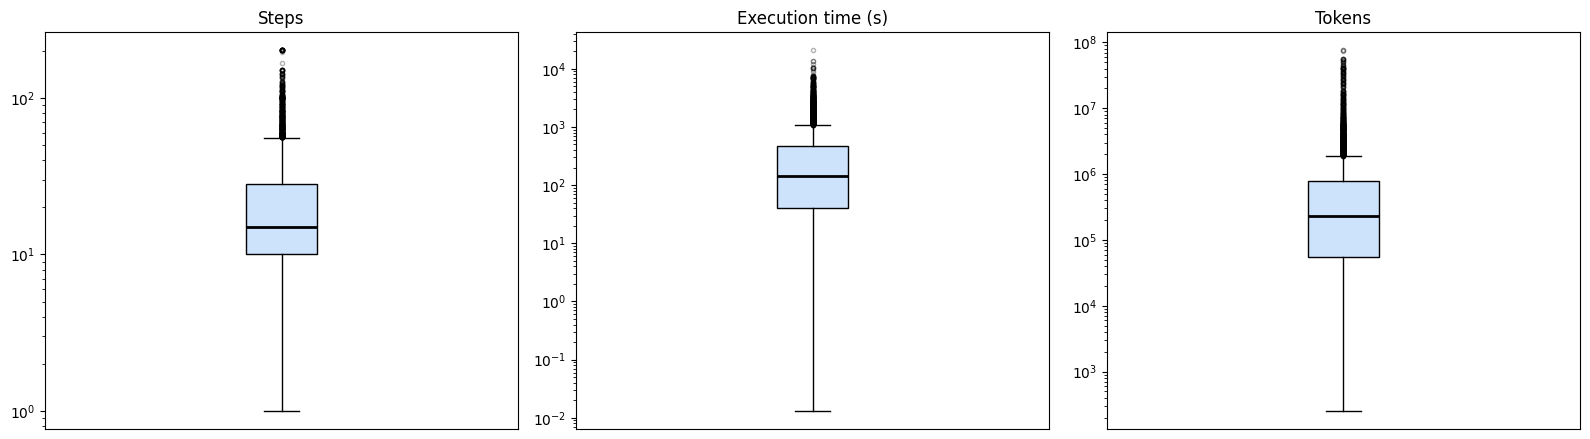

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ATTRIBUTES):
    values = df.loc[df[col] > 0, col]
    ax.boxplot(values, patch_artist=True, boxprops=dict(facecolor="#cde2fb"),
               medianprops=dict(color="black", linewidth=2), flierprops=dict(marker=".", alpha=0.3))
    ax.set_yscale("log"); ax.set_title(NAMES[col]); ax.set_xticks([])
plt.tight_layout(); plt.show()

---
# 3. Data preparation

1. Executions with no recorded tokens are removed (the token attribute is not valid).
2. Executions that consumed tokens but recorded no step (**fast failures**) are separated from the comparison and analyzed on their own.
3. Executions ended by error and extreme values are kept.
4. Task sets with an inconsistent outcome field, or whose failures come from only part of the models, are excluded from the group comparison.

## 3.1 No-token and no-step executions

In [16]:
no_tokens = df["total_tokens"] == 0
no_steps = (df["steps"] == 0) & ~no_tokens

print("No-token executions:", no_tokens.sum())
print(df.loc[no_tokens, ["benchmark", "model", "steps", OUTCOME]], "\n")
print("No-step executions (fast failures):", no_steps.sum())

data = df[~no_tokens & ~no_steps].copy()
print("Executions kept for the comparison:", len(data))

No-token executions: 7
         benchmark                 model  steps  success
5803  tau2_airline       claude-opus-4-5     13    False
6300  tau2_airline       claude-opus-4-5      4     True
6362  tau2_airline  gemini-3-pro-preview      9     True
7018   tau2_retail       claude-opus-4-5      1    False
7055   tau2_retail       claude-opus-4-5      1    False
7113   tau2_retail       claude-opus-4-5     10     True
7523   tau2_retail       claude-opus-4-5      0    False 

No-step executions (fast failures): 634
Executions kept for the comparison: 9415


## 3.2 Fast failures

In [17]:
fast = check[(check["steps"] == 0) & (check["total_tokens"] > 0)]

print("Outcome:", fast[OUTCOME].map({True: "success", False: "failure"}).value_counts().to_dict())
print(f"Share of all failures: {100 * (~fast[OUTCOME]).sum() / (~df[OUTCOME]).sum():.1f}%")
print(f"Single model call: {100 * (fast['calls'] == 1).mean():.1f}%")
print("Medians: calls", fast["calls"].median(), "| tokens", fast["total_tokens"].median(),
      "| time (s)", round(fast["execution_time"].median(), 1))
print("By harness:", fast["harness"].value_counts().to_dict())
print("By task set:", fast["benchmark"].value_counts().to_dict())

pd.DataFrame({
    "fast failures": fast["model"].value_counts(),
    "% of the model's executions": (100 * fast["model"].value_counts() / df["model"].value_counts()).round(1),
}).fillna(0)

Outcome: {'failure': 634}
Share of all failures: 15.0%
Single model call: 96.5%
Medians: calls 1.0 | tokens 7041.0 | time (s) 44.7
By harness: {'openai_solo': 376, 'claude_code': 257, 'smolagents_code': 1}
By task set: {'tau2_telecom': 262, 'tau2_retail': 251, 'tau2_airline': 117, 'swebench': 3, 'appworld': 1}


,fast failures,% of the model's executions
model,,
DeepSeek-V3.2,157.0,6.8
Kimi-K2.5,474.0,20.7
claude-opus-4-5,1.0,0.1
gemini-3-pro-preview,2.0,0.1
gpt-5.2,0.0,0.0


## 3.3 Errors and extreme values (kept)

In [18]:
print("Executions with status 'error' kept:", (data["status"] == "error").sum())

Executions with status 'error' kept: 260


## 3.4 Task sets excluded from the group comparison

In [19]:
failures_by_model = pd.crosstab(data["benchmark"], data["model"], values=~data[OUTCOME], aggfunc="sum")
criteria = pd.DataFrame({
    "(a) successes with score 0 (%)": (100 * ((data["score"] == 0) & data[OUTCOME]).groupby(data["benchmark"]).sum()
                                        / data.groupby("benchmark")[OUTCOME].sum()).round(1),
    "(b) models with no failure": (failures_by_model == 0).sum(axis=1),
    "(b) models with at most 1 failure": (failures_by_model <= 1).sum(axis=1),
})
print(failures_by_model, "\n")
criteria

model           DeepSeek-V3.2  Kimi-K2.5  claude-opus-4-5  gemini-3-pro-preview  gpt-5.2
benchmark                                                                               
appworld                465.0      453.0             71.0                 138.0      NaN
browsecompplus          265.0      241.0            153.0                 209.0    237.0
swebench                 83.0       68.0              0.0                   1.0      1.0
tau2_airline             84.0       52.0             60.0                  23.0    117.0
tau2_retail              94.0       71.0             72.0                  25.0    157.0
tau2_telecom            106.0       46.0            106.0                  34.0    157.0 



,(a) successes with score 0 (%),(b) models with no failure,(b) models with at most 1 failure
benchmark,,,
appworld,0.0,0,0
browsecompplus,0.0,0,0
swebench,33.8,1,3
tau2_airline,0.0,0,0
tau2_retail,0.9,0,0
tau2_telecom,0.0,0,0


In [20]:
EXCLUDED = ["swebench"]   # inconsistent outcome and failures concentrated in two models
comparison = data[~data["benchmark"].isin(EXCLUDED)].copy()
print("Executions in the group comparison:", len(comparison))
print(comparison["benchmark"].value_counts().sort_index())

Executions in the group comparison: 7459
benchmark
appworld          1499
browsecompplus    1948
tau2_airline       837
tau2_retail       1593
tau2_telecom      1582
Name: count, dtype: int64


---
# 4. Modeling

**Probability of superiority (PS):** the chance that a randomly chosen unsuccessful execution has a higher value than a randomly chosen successful one (ties count as half). PS = 0.5 means no separation. It equals the Mann-Whitney U statistic divided by the number of pairs.

**Compatibility interval:** 95% percentile bootstrap, 1,000 resamples drawn with replacement within each group, fixed seed (42).

In [21]:
N_BOOT = 1000
rng = np.random.default_rng(42)

def ps(failure, success):
    ranks = stats.rankdata(np.concatenate([failure, success]))
    return (ranks[:len(failure)].sum() - len(failure) * (len(failure) + 1) / 2) / (len(failure) * len(success))

def bootstrap_interval(failure, success):
    failure, success = np.asarray(failure), np.asarray(success)
    values = [ps(rng.choice(failure, len(failure)), rng.choice(success, len(success))) for _ in range(N_BOOT)]
    return np.percentile(values, [2.5, 97.5])

def compare(group, attribute, with_interval=True):
    success = group.loc[group[OUTCOME], attribute]
    failure = group.loc[~group[OUTCOME], attribute]
    test = stats.mannwhitneyu(failure, success, alternative="two-sided")
    out = {"n success": len(success), "n failure": len(failure),
           "median success": success.median(), "median failure": failure.median(),
           "p-value": test.pvalue, "PS": test.statistic / (len(failure) * len(success))}
    if with_interval:
        out.update(dict(zip(["PS low", "PS high"], bootstrap_interval(failure, success))))
    return out

## 4.1 Comparison by task set

In [22]:
rows = []
for task_set, group in comparison.groupby("benchmark"):
    for attribute in ATTRIBUTES:
        rows.append({"task set": task_set, "attribute": NAMES[attribute], **compare(group, attribute)})
results = pd.DataFrame(rows)
results["p-value"] = results["p-value"].map(lambda p: f"{p:.1e}")
results.round({"median success": 1, "median failure": 1, "PS": 2, "PS low": 2, "PS high": 2})

,task set,attribute,n success,n failure,median success,median failure,p-value,PS,PS low,PS high
0,appworld,Steps,372,1127,11.0,22.0,1.6e-20,0.66,0.63,0.70
1,appworld,Execution time (s),372,1127,233.4,643.3,1.6e-58,0.78,0.75,0.81
2,appworld,Tokens,372,1127,670042.5,1035875.0,1.4e-11,0.62,0.58,0.65
3,browsecompplus,Steps,843,1105,11.0,15.0,1.7e-16,0.61,0.58,0.64
4,browsecompplus,Execution time (s),843,1105,66.1,204.6,5.3e-33,0.66,0.63,0.68
5,browsecompplus,Tokens,843,1105,271776.0,306246.0,4.5e-02,0.53,0.50,0.55
6,tau2_airline,Steps,501,336,10.0,13.0,2.0e-17,0.67,0.63,0.71
7,tau2_airline,Execution time (s),501,336,35.4,67.8,3.5e-07,0.60,0.56,0.64
8,tau2_airline,Tokens,501,336,57515.0,102572.0,5.8e-08,0.61,0.57,0.65
9,tau2_retail,Steps,1174,419,11.0,12.0,4.1e-01,0.49,0.45,0.52


In [23]:
ps_table = results.pivot(index="task set", columns="attribute", values="PS")[[NAMES[a] for a in ATTRIBUTES]]
ps_table.round(2)

attribute,Steps,Execution time (s),Tokens
task set,,,
appworld,0.66,0.78,0.62
browsecompplus,0.61,0.66,0.53
tau2_airline,0.67,0.60,0.61
tau2_retail,0.49,0.51,0.51
tau2_telecom,0.57,0.50,0.53


## 4.2 Check: within each harness (at least 20 executions per group)

In [24]:
MIN_N = 20
rows = []
for (task_set, harness), group in comparison.groupby(["benchmark", "harness"]):
    if min(group[OUTCOME].sum(), (~group[OUTCOME]).sum()) < MIN_N:
        continue
    for attribute in ATTRIBUTES:
        r = compare(group, attribute, with_interval=False)
        rows.append({"task set": task_set, "harness": harness, "attribute": NAMES[attribute], "PS": round(r["PS"], 2)})
by_harness = pd.DataFrame(rows)
by_harness.pivot_table(index=["task set", "harness"], columns="attribute", values="PS")[[NAMES[a] for a in ATTRIBUTES]]

attribute                                      Steps  Execution time (s)  Tokens
task set       harness                                                          
appworld       openai_solo                      0.48                0.73    0.47
               smolagents_code                  0.71                0.62    0.60
               tool_calling                     0.78                0.82    0.75
               tool_calling_with_shortlisting   0.69                0.75    0.72
browsecompplus claude_code                      0.71                0.61    0.71
               openai_solo                      0.52                0.67    0.48
               smolagents_code                  0.53                0.77    0.43
               tool_calling                     0.70                0.74    0.59
tau2_airline   claude_code                      0.69                0.61    0.69
               openai_solo                      0.59                0.67    0.69
               smolagents_code                  0.75                0.69    0.69
               tool_calling                     0.67                0.61    0.65
tau2_retail    claude_code                      0.57                0.59    0.61
               openai_solo                      0.35                0.56    0.60
               smolagents_code                  0.50                0.54    0.56
               tool_calling                     0.58                0.52    0.57
tau2_telecom   claude_code                      0.55                0.47    0.55
               openai_solo                      0.42                0.51    0.55
               smolagents_code                  0.58                0.52    0.52
               tool_calling                     0.66                0.47    0.64

## 4.3 Distributions by outcome

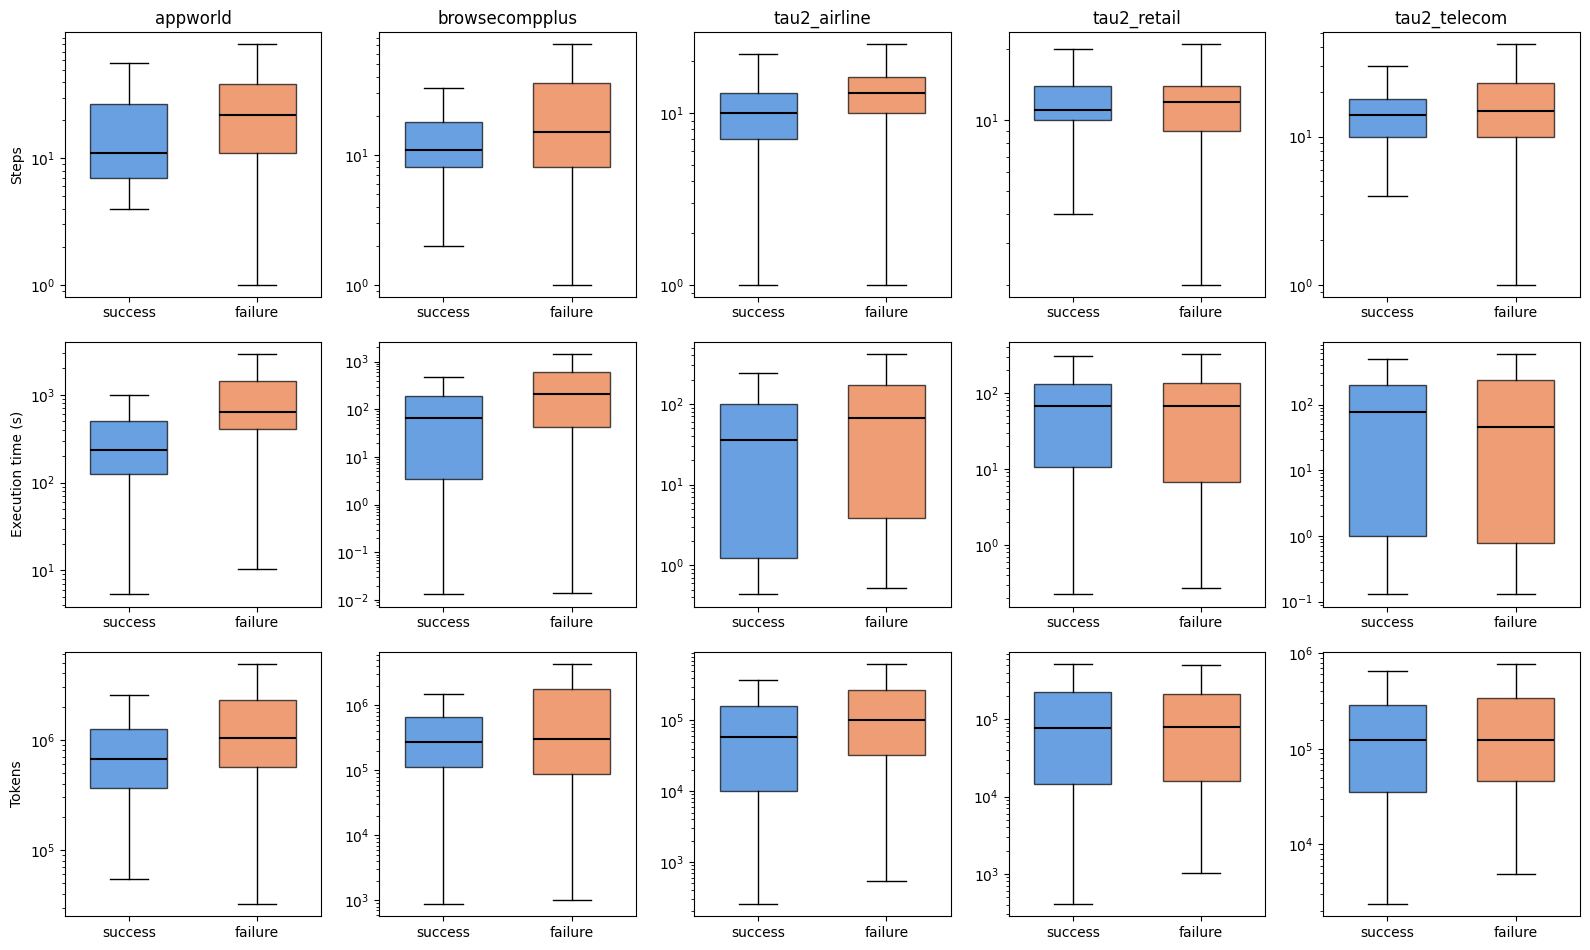

In [25]:
task_sets = sorted(comparison["benchmark"].unique())
fig, axes = plt.subplots(len(ATTRIBUTES), len(task_sets), figsize=(3.2 * len(task_sets), 3.2 * len(ATTRIBUTES)))
for i, attribute in enumerate(ATTRIBUTES):
    for j, task_set in enumerate(task_sets):
        ax = axes[i, j]
        g = comparison[comparison["benchmark"] == task_set]
        boxes = ax.boxplot([g.loc[g[OUTCOME], attribute], g.loc[~g[OUTCOME], attribute]],
                           patch_artist=True, widths=0.6, showfliers=False,
                           medianprops=dict(color="black", linewidth=1.5))
        for box, color in zip(boxes["boxes"], [COLOR_SUCCESS, COLOR_FAILURE]):
            box.set_facecolor(color); box.set_alpha(0.7)
        ax.set_yscale("log"); ax.set_xticks([1, 2], ["success", "failure"])
        if i == 0: ax.set_title(task_set)
        if j == 0: ax.set_ylabel(NAMES[attribute])
plt.tight_layout(); plt.show()

## 4.4 Check: closed-weight models only

In [26]:
OPEN_WEIGHTS = ["Kimi-K2.5", "DeepSeek-V3.2"]
closed = comparison[~comparison["model"].isin(OPEN_WEIGHTS)]
rows = []
for task_set, group in closed.groupby("benchmark"):
    for attribute in ATTRIBUTES:
        r = compare(group, attribute)
        rows.append({"task set": task_set, "attribute": NAMES[attribute], "n success": r["n success"],
                     "n failure": r["n failure"], "PS": r["PS"], "PS low": r["PS low"], "PS high": r["PS high"]})
closed_only = pd.DataFrame(rows)
closed_only.round({"PS": 2, "PS low": 2, "PS high": 2})

,task set,attribute,n success,n failure,PS,PS low,PS high
0,appworld,Steps,291,209,0.75,0.70,0.79
1,appworld,Execution time (s),291,209,0.75,0.71,0.80
2,appworld,Tokens,291,209,0.70,0.65,0.74
3,browsecompplus,Steps,550,599,0.59,0.56,0.62
4,browsecompplus,Execution time (s),550,599,0.64,0.61,0.67
5,browsecompplus,Tokens,550,599,0.59,0.56,0.63
6,tau2_airline,Steps,354,200,0.67,0.62,0.71
7,tau2_airline,Execution time (s),354,200,0.58,0.54,0.63
8,tau2_airline,Tokens,354,200,0.59,0.54,0.64
9,tau2_retail,Steps,792,254,0.48,0.44,0.52


## 4.5 Sensitivity: including the fast failures

In [27]:
with_fast = df[~no_tokens & ~df["benchmark"].isin(EXCLUDED)]
rows = []
for task_set in sorted(comparison["benchmark"].unique()):
    for attribute in ATTRIBUTES:
        without = compare(comparison[comparison["benchmark"] == task_set], attribute, with_interval=False)["PS"]
        withf = compare(with_fast[with_fast["benchmark"] == task_set], attribute, with_interval=False)["PS"]
        rows.append({"task set": task_set, "attribute": NAMES[attribute], "PS (main)": without, "PS (with fast failures)": withf})
pd.DataFrame(rows).pivot(index="task set", columns="attribute", values=["PS (main)", "PS (with fast failures)"]).round(2)

PS (main)              PS (with fast failures)             
attribute      Execution time (s) Steps Tokens      Execution time (s) Steps Tokens
task set                                                                           
appworld                     0.78  0.66   0.62                    0.78  0.66   0.62
browsecompplus               0.66  0.61   0.53                    0.66  0.61   0.53
tau2_airline                 0.60  0.67   0.61                    0.59  0.50   0.51
tau2_retail                  0.51  0.49   0.51                    0.46  0.30   0.40
tau2_telecom                 0.50  0.57   0.53                    0.47  0.36   0.37

---
# 5. Evaluation

## 5.1 Separation map and compatibility intervals

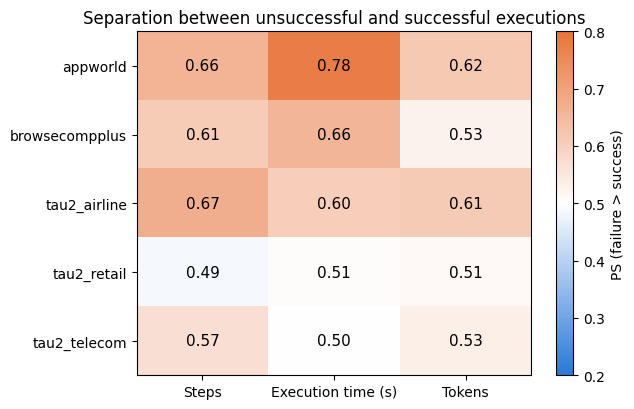

In [28]:
cmap = LinearSegmentedColormap.from_list("sep", [COLOR_SUCCESS, "#ffffff", COLOR_FAILURE])
fig, ax = plt.subplots(figsize=(6.5, 0.6 * len(ps_table) + 1.2))
im = ax.imshow(ps_table.values, cmap=cmap, vmin=0.2, vmax=0.8, aspect="auto")
ax.set_xticks(range(ps_table.shape[1]), ps_table.columns)
ax.set_yticks(range(ps_table.shape[0]), ps_table.index)
for i in range(ps_table.shape[0]):
    for j in range(ps_table.shape[1]):
        ax.text(j, i, f"{ps_table.values[i, j]:.2f}", ha="center", va="center", fontsize=11)
fig.colorbar(im, ax=ax, label="PS (failure > success)")
ax.set_title("Separation between unsuccessful and successful executions")
plt.tight_layout(); plt.show()

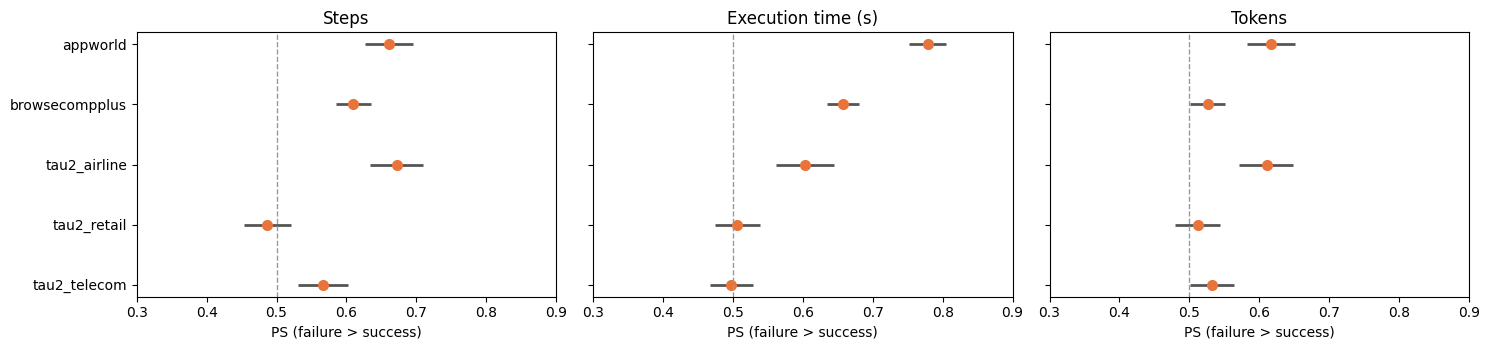

In [29]:
fig, axes = plt.subplots(1, len(ATTRIBUTES), figsize=(15, 3.6), sharey=True)
for ax, attribute in zip(axes, ATTRIBUTES):
    part = results[results["attribute"] == NAMES[attribute]].iloc[::-1]
    y = np.arange(len(part))
    ax.hlines(y, part["PS low"], part["PS high"], color="#555555", linewidth=2)
    ax.plot(part["PS"], y, "o", color=COLOR_FAILURE, markersize=7)
    ax.axvline(0.5, color="#999999", linestyle="--", linewidth=1)
    ax.set_yticks(y, part["task set"]); ax.set_xlim(0.3, 0.9)
    ax.set_title(NAMES[attribute]); ax.set_xlabel("PS (failure > success)")
plt.tight_layout(); plt.show()

## 5.2 Direction consistency across harnesses

In [30]:
overall = ps_table.stack().rename("PS overall").reset_index().rename(columns={"level_1": "attribute"})
merged = by_harness.merge(overall, on=["task set", "attribute"])
merged["same direction"] = np.sign(merged["PS"] - 0.5) == np.sign(merged["PS overall"] - 0.5)
merged.groupby(["task set", "attribute"]).agg(harnesses=("same direction", "size"),
                                              same_direction=("same direction", "sum")).unstack("attribute")

harnesses                  same_direction             
attribute      Execution time (s) Steps Tokens Execution time (s) Steps Tokens
task set                                                                      
appworld                        4     4      4                  4     3      3
browsecompplus                  4     4      4                  4     4      2
tau2_airline                    4     4      4                  4     4      4
tau2_retail                     4     4      4                  4     1      4
tau2_telecom                    4     4      4                  2     3      4

## 5.3 Summary

- Unsuccessful executions take longer and more steps in AppWorld, BrowseCompPlus and τ²-Airline (PS up to 0.78); tokens separate less.
- In τ²-Retail and τ²-Telecom, results are most compatible with no important difference.
- The pattern holds within harnesses and with closed-weight models only.
- Fast failures (one model call, no step) form a second failure type, concentrated in two open-weight models in the customer-service task sets; including them reverses the direction in those sets.
- Differences indicate association, not causation. Operational telemetry carries information about the outcome, but not enough to indicate it on its own.

---
# 6. Deployment

To apply the procedure to other OpenTelemetry GenAI traces: compute tokens from `gen_ai.usage.*`, time from the record timestamps, and steps as the number of model calls; compare by task type and agent configuration; and monitor executions with a single model call and no step.